[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simon-clematide/gemma-qlora-finetuning/blob/main/notebooks/11_colab_l4_live_demo.ipynb)

# Instruction Fine-Tuning in Practice

Follow one experiment from labeled German rail feedback to a before/after comparison of Gemma-2-2B predictions.

**Run All: attend to the first cell.** Live execution needs access to the gated [Gemma model](https://huggingface.co/google/gemma-2-2b-it). Accept its license with your Hugging Face account first. If no saved token is active or Gemma access is missing, the cell runs `login()` to display a URL and device code for browser authorization. Keep the cell running until browser authorization finishes. It verifies access before installing the project or preparing data. Replay needs no account or model weights.

Choose `REQUESTED_MODE = 'replay'` for the recorded classroom experiment, or leave `auto` to run live on CUDA. Keep tokens out of notebook code and output.

For a full training run, set `LIVE_RUN_PROFILE = 'full'` in the first cell and use a CUDA GPU. The default `classroom` profile stays short; replay always uses the existing recording.

**Learning route:** try the task → inspect supervision → predict changes → train or replay → evaluate → explain errors.


In [1]:
import importlib.util, os, subprocess, sys

REQUESTED_MODE = 'auto'  # 'auto', 'replay', or 'live' (requires CUDA)
INFERENCE_BATCH_SIZE = 8  # Reduce if GPU memory is insufficient
LIVE_RUN_PROFILE = 'classroom'  # 'classroom' or 'full' (all train, 3 epochs, all test_syn)
USE_4BIT_QUANTIZATION = True  # Live only; replay remains recorded MPS LoRA

if LIVE_RUN_PROFILE not in {'classroom', 'full'}:
    raise ValueError('Choose classroom or full for LIVE_RUN_PROFILE')

if REQUESTED_MODE not in {'auto', 'replay', 'live'}:
    raise ValueError('Choose auto, replay, or live')
cuda_available = False
if REQUESTED_MODE != 'replay' and importlib.util.find_spec('torch') is not None:
    import torch
    cuda_available = torch.cuda.is_available()
if REQUESTED_MODE == 'live' and not cuda_available:
    raise RuntimeError('LIVE mode requires CUDA. Select a GPU runtime or choose replay.')
RUN_LIVE_GPU = cuda_available and REQUESTED_MODE != 'replay'

if RUN_LIVE_GPU:
    print('LIVE: verifying gated Gemma access before setup.', flush=True)
    if importlib.util.find_spec('huggingface_hub') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'huggingface_hub'], check=True)
    from huggingface_hub import HfApi, get_token, login
    try:
        _token = get_token()
        if _token:
            try:
                HfApi().auth_check('google/gemma-2-2b-it', token=_token)
            except Exception:
                _token = None
        if not _token:
            login(skip_if_logged_in=False)
            _token = get_token()
            if not _token:
                raise RuntimeError('Login did not provide an active token.')
            HfApi().auth_check('google/gemma-2-2b-it', token=_token)
    except Exception as error:
        _status = getattr(getattr(error, 'response', None), 'status_code', None)
        raise RuntimeError(
            f'Gemma access was not verified ({type(error).__name__}, HTTP status: {_status}). '
            'Accept the Gemma license and check that your token permits reading this gated model. '
            'If a Colab HF_TOKEN secret or environment token is stale, update/remove it and restart '
            'the runtime. For connection errors, retry. Setup has not started.'
        ) from None
    finally:
        if '_token' in locals():
            del _token
    print('Gemma access verified. Continue with setup.')
else:
    print('REPLAY: recorded MPS LoRA experiment; Hugging Face login and model downloads skipped.')

REPLAY: recorded MPS LoRA experiment; Hugging Face login and model downloads skipped.


### Prepare the Workspace

Access is now verified or replay selected. This cell installs the project on Colab and prepares the bundled data.

In [2]:
import importlib, json, os, subprocess, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


if 'google.colab' in sys.modules:
    REPO_URL = os.environ.get('GERMEVAL_REPO_URL', 'https://github.com/simon-clematide/gemma-qlora-finetuning.git')
    if not Path('pyproject.toml').exists() and not Path('gemma-qlora-finetuning/pyproject.toml').exists():
        subprocess.run(['git', 'clone', '-q', REPO_URL], check=True)
    if Path('gemma-qlora-finetuning/pyproject.toml').exists():
        os.chdir('gemma-qlora-finetuning')
    subprocess.run(['git', 'fetch', '-q', 'origin', 'main'], check=True)
    subprocess.run(['git', 'reset', '-q', '--hard', 'origin/main'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'bitsandbytes>=0.46.1', '-e', '.[ml,cuda]'], check=True)

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
    os.chdir(ROOT)
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

# Evict any cached germeval_llm modules from prior runs in a warm Colab/Jupyter kernel
for _mod in [k for k in list(sys.modules) if k == 'germeval_llm' or k.startswith('germeval_llm.')]:
    sys.modules.pop(_mod, None)

from germeval_llm.convert import ensure_derived_datasets_ready
from germeval_llm.inference import detect_compute_device
from germeval_llm.replay import DEFAULT_CLASSROOM_REPLAY, load_replay_manifest

ensure_derived_datasets_ready()
hw = detect_compute_device()
EXECUTION_MODE = 'LIVE (New CUDA Experiment)' if RUN_LIVE_GPU else 'REPLAY (Recorded MPS LoRA Experiment)'
git_rev = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip() or 'unversioned workspace (recording commit is in its manifest)'
dev_label = f"{hw['gpu_name']} ({hw['gpu_vram_gb']} GB VRAM)" if hw['cuda_available'] else f"{hw['device'].upper()} (current session; replay needs no model weights)"

print('ENVIRONMENT SUMMARY')
print('─' * 52)
print(f'Repository commit:   {git_rev}')
print(f'Execution mode:      {EXECUTION_MODE}')
print(f'Compute device:      {dev_label}')
print(f'PyTorch version:     {hw.get("torch_version", "N/A")} (bf16_supported={hw["bf16_supported"]})')
print(f'Canonical dataset:   Ready (train / dev / test_syn / test_dia)')

import html
from IPython.display import HTML

def show_details(title, body_html):
    display(HTML('<details><summary>' + html.escape(title) + '</summary>' + body_html + '</details>'))

def full_text(value):
    return '<pre style="white-space:pre-wrap;overflow-wrap:anywhere">' + html.escape(str(value)) + '</pre>'


ENVIRONMENT SUMMARY
────────────────────────────────────────────────────
Repository commit:   303a6de
Execution mode:      REPLAY (Recorded MPS LoRA Experiment)
Compute device:      MPS (current session; replay needs no model weights)
PyTorch version:     2.14.1 (bf16_supported=True)
Canonical dataset:   Ready (train / dev / test_syn / test_dia)


# Part I — Experimental Design and Setup

## 1. What Can Fine-Tuning Change?

A model can understand a task description yet produce the wrong labels, the wrong output format, or both. We will investigate these two problems separately:

> **Does supervised instruction fine-tuning improve the predicted aspect–sentiment labels, the JSON format, or both?**

Our route through the experiment is:

**Read a labeled example → build its instruction and target completion → inspect the baseline → train an adapter → compare predictions on the same held-out documents.**

### Try the Task First

GermEval 2017 Task C asks for all aspect categories and their sentiment polarities in a German rail-feedback document. The model uses 19 permitted categories and the values `positive`, `neutral`, and `negative`.

Read this illustrative text before opening the suggested answer:

> *Der Zug war pünktlich, aber das Personal war unfreundlich.*

Which two aspects are discussed? Does the sentiment apply to the whole sentence or to each aspect separately?

<details>
<summary>Suggested output for this illustrative example</summary>

```json
{"labels": ["Zugfahrt:positive", "Service_und_Kundenbetreuung:negative"]}
```

The ride and the service receive different polarities. This is a set of aspect–polarity labels, not one sentiment label for the whole document. The example illustrates the output contract; it is not a canonical gold annotation.

</details>

A document with no annotated aspects has the target `{"labels": []}`. We keep these documents: inventing an aspect for an irrelevant post is a false positive. A document may also express different polarities for the same category.

### What We Compare

| System | Instructions at inference time | Task-specific parameter updates |
| :--- | :--- | :--- |
| Zero-shot baseline | `p1_guidelines`: task, categories, and input text | None |
| Fine-tuned adapter | The same instruction template and input text | Learned from labeled training examples |

Both systems are scored on the same evaluation document IDs with the same parser and metrics. This tests the effect of adding a trained adapter. A separate matched LoRA-versus-QLoRA experiment would be needed to measure the effect of quantization.

This comparison uses one guideline-based zero-shot prompt. It does not establish superiority over few-shot prompting or a prompt optimized on `dev`.

By the end, you should be able to explain where the supervision enters, why prompt tokens are excluded from the direct loss, what LoRA and QLoRA save, and what the evaluation can establish.

## 2. How to Read and Run This Notebook

The access cell above chooses an execution mode from the detected hardware:

| Mode | What happens in this session | How to interpret the results |
| :--- | :--- | :--- |
| **LIVE**: CUDA available | Generate a fresh zero-shot baseline, train an adapter, and generate its predictions | A fresh adapter run compared with the selected baseline |
| **REPLAY**: no CUDA | Load the classroom manifest, training history, and both sets of saved predictions | Analysis of a recorded experiment; no full Gemma training occurs now |

The classroom scope uses **1,000 training examples, 100 optimizer steps, and the first 150 `test_syn` documents**. These are demonstration settings, not a full benchmark.

<details>
<summary>Full-data live run</summary>

Set `LIVE_RUN_PROFILE = 'full'` before running the notebook. This uses **every training example, three epochs, and every `test_syn` document**, with the same seed, prompt, model revision, and effective batch size of 16. The step budget grows with the dataset instead of stopping after 100 updates. Validation-loss monitoring uses the first 160 dev examples; `test_dia` remains unused by this demo. Training and both inference passes take substantially longer. Live inference batches 8 documents (`INFERENCE_BATCH_SIZE` in the first cell); L4 training uses microbatch 8 × accumulation 2, keeping effective batch 16. Batched prediction latency is amortized batch wall time per document. Batching can change floating-point rounding and occasionally predictions even with greedy decoding; record new results as a separate run. Export the resulting ZIP at the end as usual. Full and classroom adapters use separate output paths.

</details>

<details>
<summary>Recording provenance and execution details</summary>

**The included replay is the fresh MPS LoRA run recorded on 18 October 2026:** Apple M4 Pro, bfloat16, no 4-bit quantization, and about **92 minutes** of training. Both baseline and adapter predictions were generated afresh. Every training example retained its complete target at a 1,152-token sequence limit. The replay verifies the bundled hashes and recorded settings before loading these artifacts.

In the access cell above, set `REQUESTED_MODE = 'replay'` to use this recording even on a CUDA machine. `auto` chooses LIVE on CUDA and REPLAY otherwise. `USE_4BIT_QUANTIZATION` controls **live training only**; it never changes the recorded method or the replay's plot labels.

Replay does not download model weights or perform training. The token table comes from an actual example's recorded training tokenization. Live runs recompute their zero-shot baseline using the selected precision and the same pinned model revision before training a new adapter.

</details>

### Verify the Experiment

The next cell verifies the recording; LIVE also checks model execution before the full run.

<details>
<summary>What the preflight checks do—and what they cannot establish</summary>

In REPLAY, the next cell verifies the compact recording bundle and skips model execution. In LIVE mode, it additionally checks whether the pieces needed by a new experiment work together:

1. **Data and provenance:** can we load the required files and match prediction IDs to gold documents?
2. **Supervision:** is the prompt present, with completion tokens available to receive loss?
3. **Execution:** can a tiny model train, save an adapter, reload it, and generate on this device?
4. **Analysis:** do scoring and plotting work, and is gated access available when requested?

The output expands these into eight checks. The training smoke test uses a **tiny, randomly initialized Gemma-shaped model**, not the full 2B checkpoint. Passing it catches integration problems early; it does not establish the full model's memory use, training time, or quality. On MPS/CPU, it also does not validate CUDA's 4-bit kernels. Read each check's details alongside its PASS status.

</details>

In [3]:
from germeval_llm.replay import DEFAULT_CLASSROOM_REPLAY, load_replay_manifest

recorded_manifest = load_replay_manifest()
REPLAY_DIR = DEFAULT_CLASSROOM_REPLAY.parent
print(f'VERIFIED RECORDING: {recorded_manifest["experiment_id"]}')
print('Recorded training: MPS LoRA (bfloat16), 1,000 examples, 100 steps')
print('Replay files: hashes and recorded training settings verified')

if RUN_LIVE_GPU:
    from germeval_llm.training import run_preflight_diagnostics
    preflight = run_preflight_diagnostics(
        check_hf_gated_access=True,
        use_4bit_quantization=USE_4BIT_QUANTIZATION,
    )
    display(pd.DataFrame(preflight['checks']))
else:
    print('REPLAY: model training, model downloads, and CUDA diagnostics skipped.')

VERIFIED RECORDING: 2026-10-18_fresh_classroom_lora_seed42
Recorded training: MPS LoRA (bfloat16), 1,000 examples, 100 steps
Replay files: hashes and recorded training settings verified
REPLAY: model training, model downloads, and CUDA diagnostics skipped.


# Part II — Task, Instructions, and Baseline

## 3. Which Data May Influence the Model?

| Split | Use in this demonstration | What it must not do |
| :--- | :--- | :--- |
| `train` | Supply labeled examples for parameter updates | Supply the reported held-out score |
| `dev` | Monitor completion loss and inform configuration choices | Become training examples |
| `test_syn` | Compare frozen systems on the same documents | Guide repeated prompt or hyperparameter tuning |
| `test_dia` | Support a later check of transfer to another time period | Be treated as measured by the `test_syn` comparison |

The next cell displays split sizes and three training examples: multiple labels, one label, and no labels. For each example, identify the input text and the target label set. Notice that the number of opinions need not equal the number of unique Task C labels: repeated annotations collapse into a set here, while the canonical records retain every opinion.

In [4]:
from germeval_llm.xml_parser import load_canonical_jsonl
from germeval_llm.convert import extract_task_c_label_sets

train_docs = load_canonical_jsonl('data/canonical/train.jsonl')
dev_docs = load_canonical_jsonl('data/canonical/dev.jsonl')
test_syn_docs = load_canonical_jsonl('data/canonical/test_syn.jsonl')
test_dia_docs = load_canonical_jsonl('data/canonical/test_dia.jsonl')

split_rows = []
for name, role, docs in [
    ('train', 'Parameter optimization (supervised learning)', train_docs),
    ('dev', 'Validation monitoring & model selection', dev_docs),
    ('test_syn', 'Held-out evaluation (same time period)', test_syn_docs),
    ('test_dia', 'Held-out evaluation (6 months later)', test_dia_docs),
]:
    rel_rate = sum(1 for d in docs if d.relevance) / len(docs)
    avg_ops = sum(len(d.opinions) for d in docs) / len(docs)
    split_rows.append({
        'Split': name,
        'Methodological Role': role,
        'Documents': f'{len(docs):,}',
        'Relevant (%)': f'{100 * rel_rate:.1f}%',
        'Mean Opinions / Doc': f'{avg_ops:.2f}',
    })
display(pd.DataFrame(split_rows))

# Select 3 representative training examples: multiple labels, one label, and irrelevant
rep_multi = next(d for d in train_docs if d.doc_id == recorded_manifest['masking_example_doc_id'])
rep_single = next(d for d in train_docs if len(extract_task_c_label_sets(d, True)[0]) == 1)
rep_irrel = next(d for d in train_docs if not d.relevance and len(d.opinions) == 0)

sample_table = []
for kind, d in [
    ('Multiple aspect–polarity labels', rep_multi),
    ('One aspect–polarity label', rep_single),
    ('Out-of-scope / irrelevant', rep_irrel),
]:
    gold_c2, _ = extract_task_c_label_sets(d, apply_typo_patches=True)
    sample_table.append({
        'Example Type': kind,
        'Relevant?': d.relevance,
        'German Input Text': d.text,
        'Gold Task C2 Labels': json.dumps({'labels': gold_c2}, ensure_ascii=False),
    })
print('\nRepresentative Training Examples:')
for row in sample_table:
    display(Markdown(f"**{row['Example Type']}**"))
    print(row['German Input Text'])
    print('Gold:', row['Gold Task C2 Labels'])

,Split,Methodological Role,Documents,Relevant (%),Mean Opinions / Doc
0,train,Parameter optimization (supervised learning),"19,432",83.4%,1.11
1,dev,Validation monitoring & model selection,"2,369",81.5%,1.06
2,test_syn,Held-out evaluation (same time period),"2,566",81.6%,1.27
3,test_dia,Held-out evaluation (6 months later),"1,842",84.0%,1.13



Representative Training Examples:


**Multiple aspect–polarity labels**

.@DB_Bahn schön das eure App mal überarbeitet wurde, aber dir GPS Funktion bei Reiseauskunft könnte man auch abstellen. Brauch ich nicht.
Gold: {"labels": ["DB_App_und_Website:positive", "DB_App_und_Website:neutral"]}


**One aspect–polarity label**

Bahn: Streik endet vorzeitig Der Streik der Gewerkschaft Deutscher Lokomotivführer (GDL) endet am 21. Mai um 19 Uhr. Die Gewerkschaft und die Deutsche Bahn haben sich auf die tariflichen Grundlagen für einen Flächentarifvertrag für das Zugpersonal und gleichzeitig auf ein Schlic
Gold: {"labels": ["Allgemein:positive"]}


**Out-of-scope / irrelevant**

Nike Free Run 3.0 V2 Damen 4357RV | dzwiannerxi -est Nike Die band air Max 90 ICE Unterhalb von der schein Sohle auf eine auf ganzer linie (umgangssprachlich) neue Stufe, gilt dieser Nike Die band air Max 90 ICE jener See-thru Effekt auf einen der wichtige erkennbar Mittelsohlen-Sneaker in dieser
Gold: {"labels": []}


About **16–19%** of documents have no opinions; most are marked irrelevant. Their empty label sets are meaningful targets. A model that always emits a rail-related label will therefore make systematic false positives.

The recorded multi-label example assigns two polarities to `DB_App_und_Website`: the annotation distinguishes the app update from the GPS feature. Task C retains both labels for the category. These are the original annotations, even where a reader might choose a different polarity.

## 4. Where Does the Supervision Enter?

For one training document, the next cell shows the same information at three levels:

- **A. Annotation:** the original text and its gold opinions.
- **B. Instruction–completion pair:** task instructions and text in the user turn, followed by the desired JSON in the model turn.
- **C. Tokens and labels:** the sequence the model reads, and the positions used as prediction targets.

At each completion position, a causal language model predicts the next token from the preceding context. During training, that context contains the gold completion prefix (*teacher forcing*); at inference time, it contains the model's own generated prefix.

| Sequence component | Direct contribution to cross-entropy loss | Still available as context? |
| :--- | :--- | :--- |
| Task instructions and input document | Excluded: label `-100` | Yes |
| Assistant delimiter `<start_of_turn>model\n` | Excluded: label `-100` | Yes |
| JSON completion and end-of-turn tokens | Included: label is the target token ID | Yes, for later positions |

`-100` is a loss-function instruction, not a token fed into the model. It does not remove the prompt from attention. The trainable adapter parameters can still receive gradients through computations involving prompt context when those computations help predict the completion. The base model's parameters remain frozen.

**Before running the cell:** predict where the labels should change from `-100` to token IDs. Then find that boundary in the token table. Why would training the model to reproduce hundreds of fixed instruction tokens distract from this task?

In [5]:
import html
from IPython.display import HTML
from germeval_llm.schemas import TaskCExample
from germeval_llm.prompts import (
    format_gemma_chat_string,
    render_task_c_user_prompt,
)

# This is an actual selected example and its recorded training tokenization.
masking_record = json.loads(Path(recorded_manifest['masking_example_file']).read_text(encoding='utf-8'))
sample_ex = TaskCExample.model_validate(masking_record['example'])
assert sample_ex.doc_id == rep_multi.doc_id and sample_ex.text == rep_multi.text

# Dynamically generate the rendered prompt and Gemma chat string from the prompt-building functions
rendered_user_prompt = render_task_c_user_prompt(sample_ex.text, prompt_key='p1_guidelines')
full_prompt_turn = format_gemma_chat_string(sample_ex.prompt, completion_messages=None, include_bos=True)
full_training_sequence_str = masking_record['formatted_training_sequence']
pretty_completion_json = json.dumps(
    json.loads(sample_ex.completion[0].content), ensure_ascii=False, indent=2
)

print('A. ORIGINAL DATASET REPRESENTATION')
print('─' * 68)
print(f'Document ID:   {rep_multi.doc_id}')
print(f'Input Text:    {rep_multi.text}')
print('Gold Opinions:')
for op in rep_multi.opinions:
    print(f'  • category={op.category!r}, polarity={op.polarity!r}, target={op.target_xml!r}')

print('\nB. INSTRUCTION–COMPLETION PAIR (Compact View with Gemma Chat-Template Boundaries)')
print('─' * 68)
prompt_lines = rendered_user_prompt.splitlines()
# Locate the taxonomy section (19 category lines) to show a compact view in the main flow
tax_idx = next(i for i, ln in enumerate(prompt_lines) if ln.startswith('Taxonomie der 19'))
pol_idx = next(i for i, ln in enumerate(prompt_lines) if ln.startswith('Erlaubte Polaritäten:'))
compact_prompt_lines = (
    ['<bos><start_of_turn>user']
    + prompt_lines[: tax_idx + 3]
    + [f'  ... [{(pol_idx - 1) - (tax_idx + 3)} additional category definitions omitted in compact view; expand full prompt below] ...']
    + prompt_lines[pol_idx - 2 :]
    + ['<end_of_turn>', '<start_of_turn>model']
)
print('1. The input sent to the model (conditioning context, masked with label = -100):\n')
print('\n'.join(compact_prompt_lines))
print('\n2. The expected completion (supervised prediction target, active in cross-entropy loss):\n')
print(pretty_completion_json)
print('<end_of_turn>\n<eos>')
print(f'\n   (Serialized single-line target in JSONL: {sample_ex.completion[0].content}<end_of_turn>)')

# Display the complete, unabridged rendered prompt (~600 tokens) in an expandable block
details_html = f'''
<details style="margin: 10px 0; padding: 8px 12px; border: 1px solid #cbd5e1; border-radius: 6px; background: #f8fafc;">
  <summary style="cursor: pointer; font-weight: 600; color: #1e293b;">
    🔍 Expand to inspect the complete, unabridged rendered training sequence (full P1_guidelines prompt + target completion)
  </summary>
  <pre style="margin-top: 8px; white-space: pre-wrap; font-size: 12px; line-height: 1.4; color: #0f172a;">{html.escape(full_training_sequence_str)}</pre>
</details>
'''
display(HTML(details_html))

mask_diag = masking_record['mask_diagnostics']
print(f'Recorded tokenizer revision: {masking_record["model_revision"]}')
print('\nC. TOKENIZED TRAINING SEQUENCE & LOSS MASKING DIAGNOSTIC')
print('─' * 68)
print(f'Total sequence tokens:       {mask_diag["total_tokens"]:4d}')
print(f'Instruction/input tokens:    {mask_diag["masked_prompt_tokens"]:4d}  (masked: label = -100)')
print(f'Completion tokens:           {mask_diag["active_completion_tokens"]:4d}')
print(f'Tokens contributing to loss: {mask_diag["active_completion_tokens"]:4d}  ({mask_diag["active_percentage"]}% of sequence)')

print('\nToken Boundary Around <start_of_turn>model\\n:')
show_details('Inspect the token IDs and loss-mask boundary', pd.DataFrame(mask_diag['boundary_preview']).to_html(index=False))

A. ORIGINAL DATASET REPRESENTATION
────────────────────────────────────────────────────────────────────
Document ID:   http://twitter.com/roxor1911/statuses/616356292333015040
Input Text:    .@DB_Bahn schön das eure App mal überarbeitet wurde, aber dir GPS Funktion bei Reiseauskunft könnte man auch abstellen. Brauch ich nicht.
Gold Opinions:
  • category='DB_App_und_Website', polarity='positive', target='App'
  • category='DB_App_und_Website', polarity='neutral', target='GPS Funktion'

B. INSTRUCTION–COMPLETION PAIR (Compact View with Gemma Chat-Template Boundaries)
────────────────────────────────────────────────────────────────────
1. The input sent to the model (conditioning context, masked with label = -100):

<bos><start_of_turn>user
Du bist ein Experte für Aspect-Based Sentiment Analysis (GermEval 2017 Task C) von deutschsprachigem Kundenfeedback zur Deutschen Bahn.
Bestimme alle im Text ausgedrückten Aspekte (sowohl explizit genannte Zielbegriffe als auch implizite Aussagen über

Recorded tokenizer revision: 299a8560bedf22ed1c72a8a11e7dce4a7f9f51f8

C. TOKENIZED TRAINING SEQUENCE & LOSS MASKING DIAGNOSTIC
────────────────────────────────────────────────────────────────────
Total sequence tokens:        849
Instruction/input tokens:     823  (masked: label = -100)
Completion tokens:             26
Tokens contributing to loss:   26  (3.06% of sequence)

Token Boundary Around <start_of_turn>model\n:


position,token,input_id,label,role_in_loss
819,'\n',108,-100,Ignored (-100: conditioning context)
820,'<start_of_turn>',106,-100,Ignored (-100: conditioning context)
821,'model',2516,-100,Ignored (-100: conditioning context)
822,'\n',108,-100,Ignored (-100: conditioning context)
823,"'{""'",9766,9766,Computed (direct completion target)
824,'labels',12488,12488,Computed (direct completion target)
825,"'"":[""'",199831,199831,Computed (direct completion target)
826,'DB',4994,4994,Computed (direct completion target)
827,'_',235298,235298,Computed (direct completion target)
828,'App',2101,2101,Computed (direct completion target)


The token table above is taken from the **actual recorded training input and loss labels**, using the pinned tokenizer revision. Read its counts rather than assuming a fixed prompt length. The complete training target includes the JSON, end-of-turn marker, and the EOS token added by the training library. Instructions remain context, with labels masked to `-100`.

### Why Keep the Instructions in German?

The input documents and category names are German, so German instructions make the task description easy to connect to the examples. The polarity strings remain the required `positive`, `neutral`, and `negative`. Both systems use the same template.

This experiment does **not** compare German and English prompts. It cannot show that prompt language caused the baseline's errors or that another language would perform worse.

## 5. What Can the Frozen Model Already Do?

We now evaluate the base model before adapter training. “Zero-shot” means no labeled demonstrations in its prompt and no GermEval adapter updates; it still receives the detailed category guidelines.

The next cell checks the recording's manifest, aligns predictions by document ID, and reports the baseline. REPLAY loads the freshly generated baseline from this recording. LIVE recomputes it using the chosen precision and pinned model revision; it does not borrow a differently configured baseline.

**Before reading the failures:** separate two questions. Did the model name the right labels? Did it obey the JSON-only instruction? A correct label set inside Markdown fences can satisfy the first question while failing exact output-format compliance.

<details>
<summary>How to interpret raw JSON compliance</summary>

**Reading “Exact JSON validity” in the next table:** a response passes only if it is a JSON object by itself, contains a `labels` list, and all labels use the permitted taxonomy. Markdown fences or introductory prose fail this measure, even if the parser can recover the labels. “Exact” does not mean matching the gold answer: validly formatted wrong labels can still pass. Section 9 works through examples.


A consistent Markdown wrapper is fixable with a deterministic adapter. We therefore treat unwrapped JSON as a secondary interface preference. The primary format measure is usable task output after permitted parsing; C1/C2 already use the extracted labels, so fences themselves incur no F1 penalty.


</details>

In [6]:
from germeval_llm.inference import (
    load_gemma_model_and_tokenizer,
    build_hf_generator_fn,
    build_hf_batch_generator_fn,
    run_task_c_inference_with_generator,
    save_predictions_jsonl,
    load_predictions_jsonl,
)
from germeval_llm.evaluation import (
    align_predictions,
    evaluate_task_c_predictions,
    verify_experiment_manifest,
)

# The supported classroom replay is the fresh, fully recorded 1,000-example run.
MANIFEST_PATH = DEFAULT_CLASSROOM_REPLAY
exp_manifest = dict(recorded_manifest)
if RUN_LIVE_GPU:
    method_tag = 'qlora_4bit' if USE_4BIT_QUANTIZATION else 'lora_16bit'
    exp_manifest['experiment_id'] = f'live_{LIVE_RUN_PROFILE}_{method_tag}_seed42'
    exp_manifest['experiment_type'] = 'live_classroom_experiment'

TRAIN_SUBSET_SIZE = exp_manifest['training_subset_size']
MAX_TRAIN_STEPS = exp_manifest['max_steps']
EVAL_MAX_DOCS = exp_manifest['evaluation_num_docs']
SEED = int(exp_manifest['seed'])
if RUN_LIVE_GPU and LIVE_RUN_PROFILE == 'full':
    from germeval_llm.training import compute_training_budget
    TRAIN_SUBSET_SIZE = len(train_docs)
    MAX_TRAIN_STEPS = int(compute_training_budget(
        TRAIN_SUBSET_SIZE, effective_batch_size=16, target_epochs=3,
    )['max_steps'])
    EVAL_MAX_DOCS = len(test_syn_docs)
    exp_manifest.update(
        training_subset_size=TRAIN_SUBSET_SIZE,
        max_steps=MAX_TRAIN_STEPS,
        evaluation_num_docs=EVAL_MAX_DOCS,
        evaluation_doc_ids=[doc.doc_id for doc in test_syn_docs],
        sampling_strategy='all',
    )
eval_docs = test_syn_docs[:EVAL_MAX_DOCS]

# Verify manifest consistency against active evaluation documents and prompt
verify_experiment_manifest(
    exp_manifest,
    expected_split='test_syn',
    expected_prompt_id='p1_guidelines',
    expected_eval_docs=eval_docs,
    expected_base_model='google/gemma-2-2b-it',
)

if RUN_LIVE_GPU:
    base_model, tokenizer = load_gemma_model_and_tokenizer(
        model_id=exp_manifest['base_model'],
        revision=exp_manifest['model_revision'],
        load_in_4bit=USE_4BIT_QUANTIZATION,
    )
    gen_fn = build_hf_generator_fn(base_model, tokenizer, max_new_tokens=128)
    batch_gen_fn = build_hf_batch_generator_fn(base_model, tokenizer, max_new_tokens=128)
    raw_baseline_preds = run_task_c_inference_with_generator(
        eval_docs,
        run_id='live_baseline_p1',
        split='test_syn',
        generate_fn=gen_fn,
        generate_batch_fn=batch_gen_fn,
        batch_size=INFERENCE_BATCH_SIZE,
        prompt_key='p1_guidelines',
    )
    del gen_fn, batch_gen_fn, base_model
    import torch; torch.cuda.empty_cache()
else:
    raw_baseline_preds = load_predictions_jsonl(exp_manifest['baseline_prediction_file'])

baseline_preds = align_predictions(eval_docs, raw_baseline_preds, expected_split='test_syn')
baseline_metrics = evaluate_task_c_predictions(eval_docs, baseline_preds, apply_gold_typo_patches=exp_manifest['gold_typo_patches'])

print('ZERO-SHOT BASELINE SUMMARY (Frozen google/gemma-2-2b-it)')
print('─' * 56)
print(f'Verified manifest:               {exp_manifest["experiment_id"]} ({exp_manifest["experiment_type"]})')
print(f'Aligned evaluation documents:    {len(baseline_preds)} (split={exp_manifest["evaluation_split"]}, prompt={exp_manifest["prompt_id"]})')
print(f'Valid JSON (exact raw output):   {baseline_metrics["valid_exact_rate"]:.4f}')
print(f'Usable task output (tolerant):  {baseline_metrics["schema_validity_rate"]:.4f}')
print(f'Parse status breakdown:          {baseline_metrics["parse_status_counts"]}')
print(f'Category micro-F1 (Task C1):     {baseline_metrics["task_c1_category_strict"]["micro_f1"]:.4f}')
print(f'Category+sentiment F1 (Task C2): {baseline_metrics["task_c2_category_sentiment_strict"]["micro_f1"]:.4f}')

# Inspect 3 distinct baseline failure modes to motivate supervised fine-tuning
failure_rows = []
seen_statuses = set()
for target_status in ('VALID_FENCED', 'INVALID_SCHEMA', 'UNKNOWN_LABEL', 'INVALID_JSON'):
    for doc, bp in zip(eval_docs, baseline_preds):
        gold_c2, _ = extract_task_c_label_sets(doc, apply_typo_patches=exp_manifest['gold_typo_patches'])
        if bp.parse_status == target_status and (set(bp.parsed_labels) != set(gold_c2) or len(gold_c2) > 0):
            failure_rows.append({
                'Failure Mode': target_status,
                'Input Text': doc.text[:85] + ('...' if len(doc.text) > 85 else ''),
                'Gold Labels': gold_c2,
                'Zero-Shot Parsed': bp.parsed_labels,
                'Raw Output Snippet': repr(bp.raw_output[:70]),
            })
            seen_statuses.add(target_status)
            break
    if len(failure_rows) == 3:
        break
print('\nSample Zero-Shot Baseline Failures (3 Distinct Failure Modes):')
show_details('Inspect baseline failure examples', pd.DataFrame(failure_rows).to_html(index=False, escape=True))

# A fixed outer-fence removal rule: no syntax repair, schema repair, or label correction.
import re
from germeval_llm.parsing import parse_task_c_output
fence_count = syntax_after_wrapper = task_after_wrapper = 0
for prediction in baseline_preds:
    raw = prediction.raw_output.strip()
    fence = re.fullmatch(r'```[^\n`]*\n(.*?)\n```', raw, flags=re.DOTALL)
    normalized = fence.group(1).strip() if fence else raw
    fence_count += int(fence is not None)
    try:
        json.loads(normalized)
        syntax_after_wrapper += 1
    except json.JSONDecodeError:
        pass
    _, normalized_status, _ = parse_task_c_output(normalized)
    task_after_wrapper += int(normalized_status == 'VALID_EXACT')
print('\nFIXABLE WRAPPER AUDIT (baseline)')
print(f'Complete outer code fences:             {fence_count}/{len(baseline_preds)}')
print(f'JSON syntax valid after fence removal:  {syntax_after_wrapper}/{len(baseline_preds)}')
print(f'Valid task output after fence removal:  {task_after_wrapper}/{len(baseline_preds)}')
print('Label scores already tolerate wrappers; removing them does not improve the reported F1.')


ZERO-SHOT BASELINE SUMMARY (Frozen google/gemma-2-2b-it)
────────────────────────────────────────────────────────
Verified manifest:               2026-10-18_fresh_classroom_lora_seed42 (recorded_classroom_experiment)
Aligned evaluation documents:    150 (split=test_syn, prompt=p1_guidelines)
Valid JSON (exact raw output):   0.0000
Usable task output (tolerant):  0.5667
Parse status breakdown:          {'VALID_FENCED': 85, 'INVALID_SCHEMA': 50, 'INVALID_JSON': 6, 'UNKNOWN_LABEL': 9}
Category micro-F1 (Task C1):     0.1323
Category+sentiment F1 (Task C2): 0.1008

Sample Zero-Shot Baseline Failures (3 Distinct Failure Modes):


Failure Mode,Input Text,Gold Labels,Zero-Shot Parsed,Raw Output Snippet
VALID_FENCED,screams @ deutsche bahn.,[Allgemein:neutral],[Image:negative],"'```json\n{""labels"": [""Image:negative""]}\n```'"
INVALID_SCHEMA,Streik der GDL: Bahn will Streik in letzter Minute verhindern: ...,[Allgemein:negative],[],"'```json\n{""labels"": [\n {""category"": ""Image"", ""polarity"": ""negative""},\n'"
UNKNOWN_LABEL,"Re: HNA Na, kommt der Winter jetzt. Verspätet, wie die Deutsche Bahn",[Zugfahrt:negative],[],"'```json\n{""labels"": [""Zugfahrt:Negative"", ""Image:Negative""]}\n```'"



FIXABLE WRAPPER AUDIT (baseline)
Complete outer code fences:             144/150
JSON syntax valid after fence removal:  143/150
Valid task output after fence removal:  84/150
Label scores already tolerate wrappers; removing them does not improve the reported F1.


### Form a Prediction Before Training

Use the actual baseline table and raw outputs above:

1. Find a formatting failure and a label-selection failure. What evidence distinguishes them?
2. Compare **unwrapped task JSON** with **usable task output after parsing**. Which errors disappear under a fixed wrapper-removal rule, and which remain?
3. Predict which will change more after training: usable task output, category F1, or category-plus-sentiment F1. State what would count as evidence against your prediction.

The shown failure cases illustrate possible problems. They are selected examples, not an estimate of how frequently each problem occurs.

---
# Part III — Parameter-Efficient Fine-Tuning and Optimization

## 6. Parameter-Efficient Fine-Tuning (LoRA and QLoRA)

To interpret this experiment accurately, we must distinguish three separate concepts:
1. **Supervised Instruction Fine-Tuning (the learning mechanism):** Presenting labeled `(instruction, completion)` examples and minimizing cross-entropy loss on the target completions. *This is what changes the model's classification and formatting behavior.*
2. **LoRA — Low-Rank Adaptation (parameter efficiency):** Updating low-rank adapter matrices instead of all pretrained weights so optimization requires a tiny fraction of parameters and optimizer states.
3. **QLoRA — Quantized LoRA (memory efficiency):** Storing the frozen base weights in 4-bit precision while training the 16-bit LoRA adapters, reducing GPU memory consumption.

### First: LoRA Conceptually
For a pretrained linear projection matrix $W_0 \in \mathbb{R}^{d_{\text{out}} \times d_{\text{in}}}$, LoRA freezes $W_0$ and adds a low-rank update:

$$
W = W_0 + \frac{\alpha}{r} B A
$$

- $W_0$: Pretrained weights, kept **frozen** (`requires_grad = False`).
- $A \in \mathbb{R}^{r \times d_{\text{in}}},\; B \in \mathbb{R}^{d_{\text{out}} \times r}$: Small **trainable** adapter matrices.
- $r$: Adapter rank ($r = 16 \ll d_{\text{in}}, d_{\text{out}}$).
- $\alpha$: Scaling factor ($\alpha = 32$, so $\alpha / r = 2.0$).

**Connection to our experiment:** Instead of updating ~2.61 billion pretrained parameters, we optimize approximately **20.8 million** adapter parameters (**0.79%** of the model).

### Second: QLoRA Conceptually
QLoRA reduces memory requirements further by storing the frozen base weights $W_0$ in a 4-bit NormalFloat (`NF4`) quantized representation while keeping the trainable adapters ($A, B$) in 16-bit precision:

| Property | LoRA (`USE_4BIT_QUANTIZATION = False`) | QLoRA (`USE_4BIT_QUANTIZATION = True`) |
| :--- | :--- | :--- |
| **Base weights ($W_0$)** | Frozen | Frozen |
| **Base representation** | 16-bit (`bfloat16` / `float16`) | 4-bit (`NF4` with double quantization) |
| **Trainable parameters ($A, B$)** | Low-rank adapters (16-bit) | Low-rank adapters (16-bit) |
| **Main advantage** | No 4-bit dequantization overhead | Smaller frozen base-weight storage |

<details>
<summary><b>Advanced: Which transformer parameters are adapted inside Gemma-2-2B? (Click to expand)</b></summary>

Inside each of the 26 transformer blocks of `google/gemma-2-2b-it`, LoRA adapters ($r=16$) are attached to all **7 linear projections** (4 in Grouped-Query Attention + 3 in the GeGLU feed-forward network):

```text
                        Output Activation h = h_base + h_lora
                                       ▲
                                      (+)
         ┌─────────────────────────────┴─────────────────────────────┐
         │  h_base = W_0 · x                     h_lora = (α/r) · B · (A · x)
┌────────┴────────────────────────┐          ┌───────────────────────┴─────────┐
│   FROZEN BASE WEIGHT W_0        │          │   TRAINABLE LoRA ADAPTER (B·A)  │
│ • 4-bit NF4 or 16-bit bf16/fp16 │          │ • Matrix B [d_out × r=16]       │
│ • requires_grad = False         │          │ • Matrix A [r=16 × d_in]        │
└─────────────────────────────────┘          └─────────────────────────────────┘

  LAYER l ∈ {1 ... 26}:
    • Attention: q_proj (2304→2048), k_proj (2304→1024), v_proj (2304→1024), o_proj (2048→2304)
    • GeGLU MLP: gate_proj (2304→9216), up_proj (2304→9216), down_proj (9216→2304)
    • Token embeddings & RMSNorms: Frozen
```
</details>

---
## 7. Training Configuration

The classroom configuration uses a **1,000-example training subset**, **100 optimizer steps**, and **150 held-out evaluation documents**. The sampler seeks category coverage and includes empty-label examples; it does not guarantee that every rare category keeps its full-dataset proportion.

An optimizer step is an update to the adapter parameters, not one document. With effective batch size 16, 100 steps correspond to roughly 1,600 training-example presentations—about 1.6 passes over a 1,000-example subset, subject to batch boundaries. Gradient accumulation lets several smaller batches contribute to one update.

The next cell reports the selected configuration and distinguishes the current session from the hardware that produced the recording. Distinguish **estimated parameter/memory profiles** from **measured training time and peak CUDA memory**, which appear after live training. In REPLAY, those measurements describe the recorded run's hardware.

**Check your understanding:** which setting changes how many weights are trainable, which changes frozen-weight storage, and which changes how many updates are made? Could this single before/after experiment establish that QLoRA outperforms LoRA?

In [7]:
from germeval_llm.training import load_training_config, estimate_gemma_parameter_and_memory_profile

if RUN_LIVE_GPU:
    import yaml
    METHOD_TAG = 'qlora_4bit' if USE_4BIT_QUANTIZATION else 'lora_16bit'
    METHOD_LABEL = 'Live QLoRA (4-bit NF4)' if USE_4BIT_QUANTIZATION else 'Live LoRA (16-bit)'
    cfg_dict = load_training_config('configs/qlora.yaml' if USE_4BIT_QUANTIZATION else 'configs/lora.yaml')
    if 'L4' in str(hw.get('gpu_name', '')).upper():
        cfg_dict['training']['per_device_train_batch_size'] = 8
        cfg_dict['training']['gradient_accumulation_steps'] = 2
    cfg_dict['model_revision'] = exp_manifest['model_revision']
    cfg_dict['training']['max_seq_length'] = exp_manifest['max_seq_length']
    TRAIN_CONFIG = f'results/runs/colab_{LIVE_RUN_PROFILE}_{METHOD_TAG}_training.yaml'
    Path(TRAIN_CONFIG).parent.mkdir(parents=True, exist_ok=True)
    Path(TRAIN_CONFIG).write_text(yaml.safe_dump(cfg_dict), encoding='utf-8')
    ADAPTER_DIR = f'models/adapters/colab_{LIVE_RUN_PROFILE}_{METHOD_TAG}_task_c'
    FT_PRED_PATH = f'results/predictions/colab_{LIVE_RUN_PROFILE}_{METHOD_TAG}_r16_test_syn.jsonl'
    run_hardware = dev_label
else:
    METHOD_TAG = 'recorded_mps_lora'
    METHOD_LABEL = 'Recorded MPS LoRA (bfloat16)'
    TRAIN_CONFIG = exp_manifest['training_config_file']
    cfg_dict = load_training_config(TRAIN_CONFIG)
    ADAPTER_DIR = None  # No adapter weights are needed or loaded during replay.
    FT_PRED_PATH = exp_manifest['finetuned_prediction_file']
    run_hardware = exp_manifest['hardware']['system_details']['machdep.cpu.brand_string'] + ' / MPS'

prof = estimate_gemma_parameter_and_memory_profile(
    lora_rank=int(cfg_dict['peft']['r']),
    quantization='nf4_4bit' if cfg_dict.get('load_in_4bit') else 'bf16_16bit',
)
print('EXPERIMENT SETUP')
print('─' * 52)
print(f'Experiment ID:       {exp_manifest["experiment_id"]}')
print(f'Execution mode:      {EXECUTION_MODE}')
print(f'Current session:     {dev_label}')
print(f'Run hardware:        {run_hardware}')
print(f'Method:              {METHOD_LABEL}')
print(f'Model revision:      {exp_manifest["model_revision"]}')
print(f'Adapter rank:        {prof["lora_rank"]} (alpha={cfg_dict["peft"]["lora_alpha"]})')
print(f'Trainable params:    {prof["trainable_parameters"]:,} ({prof["trainable_percent"]:.2f}%; configuration estimate)')
print(f'Training examples:   {TRAIN_SUBSET_SIZE:,} ({exp_manifest["sampling_strategy"]})')
print(f'Maximum steps:       {MAX_TRAIN_STEPS:,}')
print(f'Sequence limit:      {cfg_dict["training"]["max_seq_length"]:,} tokens (complete selected targets)')
print(f'Evaluation examples: {len(eval_docs):,} (held-out {exp_manifest["evaluation_split"]})')
print(f'Random seed:         {SEED}')

EXPERIMENT SETUP
────────────────────────────────────────────────────
Experiment ID:       2026-10-18_fresh_classroom_lora_seed42
Execution mode:      REPLAY (Recorded MPS LoRA Experiment)
Current session:     MPS (current session; replay needs no model weights)
Run hardware:        Apple M4 Pro / MPS
Method:              Recorded MPS LoRA (bfloat16)
Model revision:      299a8560bedf22ed1c72a8a11e7dce4a7f9f51f8
Adapter rank:        16 (alpha=32)
Trainable params:    20,766,720 (0.79%; configuration estimate)
Training examples:   1,000 (stratified)
Maximum steps:       100
Sequence limit:      1,152 tokens (complete selected targets)
Evaluation examples: 150 (held-out test_syn)
Random seed:         42


## 8. What Should the Loss Curve Tell Us?

The next cell trains the adapter in LIVE mode or loads the recorded training history in REPLAY. It separates training-loss events from validation-loss events; they may occur at different steps.

Completion cross-entropy measures how much probability the model assigns to the gold next tokens. Lower loss means better prediction of those completions under teacher forcing. It is not an F1 score and does not directly measure whether free generation returns the correct label set.

**Before viewing the curve:** sketch two possible outcomes. What would you expect if training loss falls while validation loss rises? What if both fall? Remember that training uses dropout and changing batches, so the two curves need not match in height.

step,loss,learning_rate,epoch
10,1.488741,1.991264e-04,0.160
20,0.357233,1.894729e-04,0.320
30,0.294942,1.701237e-04,0.480
40,0.261125,1.431754e-04,0.640
50,0.222005,1.115485e-04,0.800
60,0.229315,7.867004e-05,0.960
70,0.181940,4.810304e-05,1.112
80,0.159036,2.315989e-05,1.272
90,0.150202,6.543554e-06,1.432
100,0.145668,5.467427e-08,1.592



TRAINING COMPLETED
────────────────────────────────────────────────
Optimization steps:       100
Training examples:        1,000
Trainable parameters:     20.77M (0.79%)
Training duration:        91m 57s (MPS)
Peak GPU memory:          N/A (recorded on MPS)
Mean training loss (whole run):      0.3490
Final validation loss:    0.1355
Adapter weights:          saved in the source run; not loaded during replay


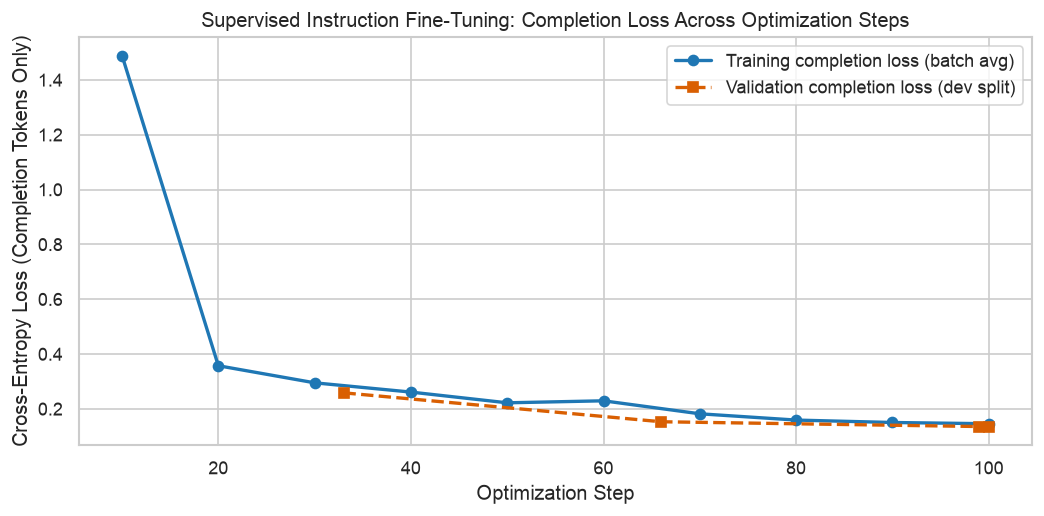

In [8]:
from germeval_llm.training import (
    run_sft_adapter_training,
    extract_training_and_eval_series,
)
from germeval_llm.reporting import plot_training_and_validation_loss

if RUN_LIVE_GPU:
    train_summary = run_sft_adapter_training(
        config_path=TRAIN_CONFIG,
        train_jsonl_path='data/derived/task_c/train.jsonl',
        dev_jsonl_path='data/derived/task_c/dev.jsonl',
        output_adapter_dir=ADAPTER_DIR,
        subset_size=TRAIN_SUBSET_SIZE,
        max_steps_override=MAX_TRAIN_STEPS,
        sampling_strategy=exp_manifest['sampling_strategy'],
        seed_override=SEED,
    )
    import torch; torch.cuda.empty_cache()
else:
    log_path = exp_manifest['training_log_file']
    train_summary = json.loads(Path(log_path).read_text(encoding='utf-8'))

train_history, eval_history = extract_training_and_eval_series(train_summary.get('log_history', []))

history_html = '<h4>Training batches</h4>' + pd.DataFrame(train_history).to_html(index=False)
if eval_history:
    history_html += '<h4>Held-out development loss</h4>' + pd.DataFrame(eval_history).to_html(index=False)
show_details('Inspect logged loss values and learning rates', history_html)

dur_sec = float(train_summary.get('train_wall_sec', 0.0))
mins, secs = divmod(int(round(dur_sec)), 60)
vram_gb = train_summary.get('peak_vram_mb', 0.0) / 1024.0
vram_str = f'{vram_gb:.2f} GB (measured CUDA)' if vram_gb > 0 else f'N/A (recorded on {train_summary.get("device", "mps").upper()})'
final_val_str = f'{eval_history[-1]["eval_loss"]:.4f}' if eval_history else 'N/A'

print('\nTRAINING COMPLETED')
print('─' * 48)
print(f'Optimization steps:       {train_summary["max_steps"]:,}')
print(f'Training examples:        {train_summary["train_examples"]:,}')
print(f'Trainable parameters:     {train_summary["trainable_parameters"] / 1e6:.2f}M ({100 * train_summary["trainable_parameters"] / train_summary["total_parameters"]:.2f}%)')
print(f'Training duration:        {mins}m {secs:02d}s ({train_summary.get("device", "unknown").upper()})')
print(f'Peak GPU memory:          {vram_str}')
print(f'Mean training loss (whole run):      {train_summary["train_loss"]:.4f}')
print(f'Final validation loss:    {final_val_str}')
if RUN_LIVE_GPU:
    print(f'Adapter saved to:         {train_summary["adapter_dir"]}')
else:
    print('Adapter weights:          saved in the source run; not loaded during replay')

fig_loss = plot_training_and_validation_loss(train_history, eval_history)
plt.show()
plt.close(fig_loss)

Read the curve before drawing a conclusion:

- Does the training loss decrease over the run?
- Does validation loss improve, flatten, or begin to rise? Which checkpoint would you investigate using `dev` alone?
- Do the summary's device and duration describe this session or a recording?

In the included recording, validation loss decreases from about 0.258 at step 33 to 0.153 at step 66 and 0.135 at the end. This supports improved completion prediction on the evaluated development examples. It does not yet establish better generated labels. We now test that separate claim on the fixed `test_syn` slice.

# Part IV — Evaluation and Interpretation

## 9. Did the Predictions Improve?

We compare both systems on the same documents using the same parser.

| Measure | Question it answers |
| :--- | :--- |
| Usable task output | Could the tolerant parser extract a valid task label list? |
| Category micro-F1 (C1) | Were the correct categories predicted, ignoring polarity? |
| Category + sentiment micro-F1 (C2) | Were the correct category–polarity pairs predicted? |

**C1/C2 measure end-to-end task performance.** They tolerate removable wrappers, but schema and unknown-label failures still affect the predictions being scored. A gain therefore does not isolate better classification from better output-contract adherence.

### Your Turn: Score One Prediction

Gold is `Zugfahrt:positive` and `Service_und_Kundenbetreuung:negative`. The prediction returns the same categories, both with `negative` polarity.

Write down TP, FP, FN, and F1 for C1 and C2. Does the document count as an exact match?

<details>
<summary>Check your calculation</summary>

C1: TP = 2, FP = 0, FN = 0, so F1 = 1. C2: TP = 1, FP = 1, FN = 1, so F1 = 0.5. Document exact match is false. Across documents, micro-F1 pools counts before computing $2TP/(2TP+FP+FN)$. Predictions on empty-gold documents contribute false positives.

</details>

### Your Turn: Diagnose Output Failures

For gold `Zugfahrt:positive`, classify each response: wrapper, schema, taxonomy, or semantic error. Which can fixed fence removal solve?

1. The correct task JSON inside Markdown code fences.
2. `{"labels": [{"category": "Zugfahrt", "polarity": "positive"}]}`
3. `{"labels": ["Train:positive"]}`
4. `{"labels": ["Zugfahrt:negative"]}`

<details>
<summary>Check the distinctions; exact JSON versus usable output</summary>

1. Wrapper: tolerant parsing accepts it; fence removal solves the raw interface issue.
2. Schema: the required list contains strings, not objects.
3. Taxonomy: `Train` is not a permitted category.
4. Semantic: valid task output, wrong polarity.

Exact task JSON (`VALID_EXACT`) requires an unwrapped JSON object with a valid `labels` list and permitted labels. It does not require gold correctness, fixed indentation, or label order. We report this interface preference in the secondary table. Both systems' label scores already tolerate wrappers; removing fences alone does not improve F1.

</details>

### Predict, Then Run

Record your predicted direction of change for usable output, C1, and C2, and one observation that would challenge your explanation. Then inspect the next cell.

<details>
<summary>How to read the paired bootstrap interval</summary>

Each of 1,000 draws samples documents with replacement and uses the same sampled IDs for both systems, then recomputes $\Delta F_1 = F_{1,\mathrm{fine\text{-}tuned}} - F_{1,\mathrm{baseline}}$. This preserves the paired comparison. An interval above zero indicates a gain consistent across these resamples; one crossing zero does not clearly resolve the direction.

This interval measures resampling variation within the fixed slice, not retraining variability or representativeness of the first 150 documents.

</details>


BEFORE VS. AFTER COMPARISON (2026-10-18_fresh_classroom_lora_seed42, n = 150 test_syn docs)


,Metric,Zero-shot,Fine-tuned,Change (Δ),95% Paired Bootstrap CI (Δ)
0,Usable task output (tolerant parser),0.5667,0.9800,+0.4133,—
1,Category micro-F1 (Task C1),0.1323,0.6667,+0.5344,"[+0.4419, +0.6289]"
2,Category + sentiment micro-F1 (Task C2),0.1008,0.5985,+0.4978,"[+0.4091, +0.5863]"


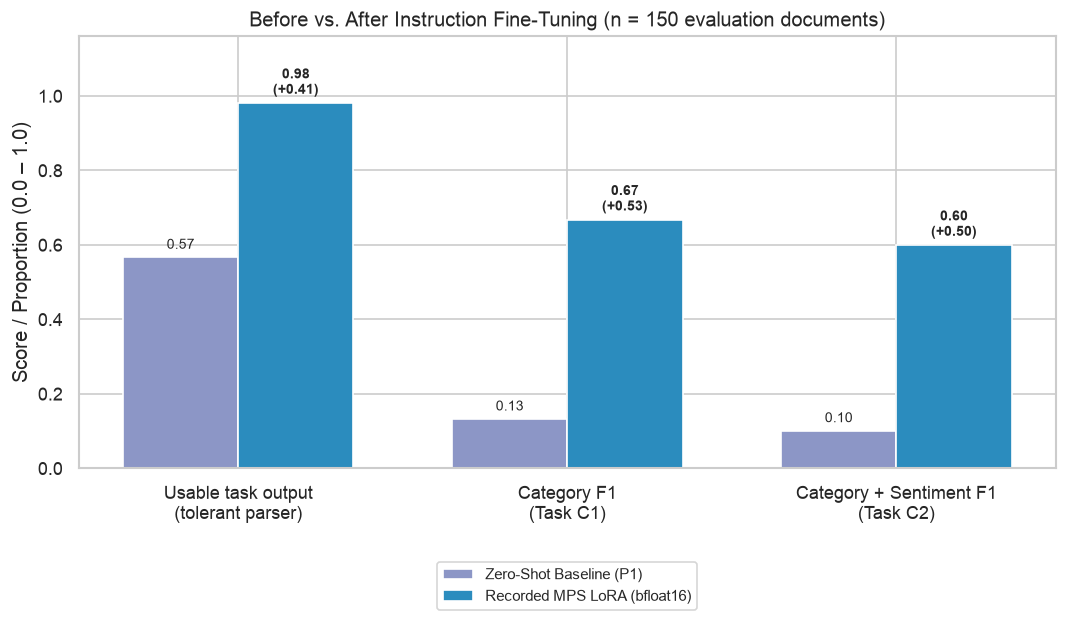


Secondary & Legacy Benchmark Metrics:


Advanced / Secondary Metric,Zero-shot,Fine-tuned,Change (Δ)
Unwrapped task JSON (raw compliance),0.0000,0.9800,+0.9800
Document-level exact-set accuracy,0.1400,0.5867,+0.4467
Official Java-compatible F1 (EvaluationScript.jar),0.0531,0.4271,+0.3740


System,Same selected documents,C2 micro-F1
Zero-shot,85,0.127660
Fine-tuned,85,0.624113


In [9]:
from germeval_llm.evaluation import compare_task_c_models
from germeval_llm.reporting import plot_before_after_metrics_comparison

if RUN_LIVE_GPU:
    ft_model, tokenizer = load_gemma_model_and_tokenizer(
        model_id=exp_manifest['base_model'],
        revision=exp_manifest['model_revision'],
        adapter_path=ADAPTER_DIR,
        load_in_4bit=USE_4BIT_QUANTIZATION,
    )
    ft_gen_fn = build_hf_generator_fn(ft_model, tokenizer, max_new_tokens=128)
    ft_batch_gen_fn = build_hf_batch_generator_fn(ft_model, tokenizer, max_new_tokens=128)
    raw_ft_preds = run_task_c_inference_with_generator(
        eval_docs,
        run_id=f'colab_{METHOD_TAG}_r16',
        split='test_syn',
        generate_fn=ft_gen_fn,
        generate_batch_fn=ft_batch_gen_fn,
        batch_size=INFERENCE_BATCH_SIZE,
        prompt_key='p1_guidelines',
    )
    save_predictions_jsonl(raw_ft_preds, FT_PRED_PATH)
    del ft_gen_fn, ft_batch_gen_fn, ft_model
    import torch; torch.cuda.empty_cache()
else:
    raw_ft_preds = load_predictions_jsonl(exp_manifest['finetuned_prediction_file'])

ft_preds = align_predictions(eval_docs, raw_ft_preds, expected_split='test_syn')
comparison = compare_task_c_models(
    eval_docs,
    baseline_preds,
    ft_preds,
    expected_split='test_syn',
    apply_gold_typo_patches=exp_manifest['gold_typo_patches'],
    n_bootstrap=1000,
    seed=SEED,
)

b_m = comparison['baseline']
q_m = comparison['finetuned']
d_m = comparison['deltas']
c1_ci = comparison['paired_bootstrap_c1']
c2_ci = comparison['paired_bootstrap_c2']

primary_df = pd.DataFrame([
    {
        'Metric': 'Usable task output (tolerant parser)',
        'Zero-shot': f'{b_m["schema_validity_rate"]:.4f}',
        'Fine-tuned': f'{q_m["schema_validity_rate"]:.4f}',
        'Change (Δ)': f'{d_m["schema_validity_rate"]:+.4f}',
        '95% Paired Bootstrap CI (Δ)': '—',
    },
    {
        'Metric': 'Category micro-F1 (Task C1)',
        'Zero-shot': f'{b_m["task_c1_category_strict"]["micro_f1"]:.4f}',
        'Fine-tuned': f'{q_m["task_c1_category_strict"]["micro_f1"]:.4f}',
        'Change (Δ)': f'{d_m["c1_strict_micro_f1"]:+.4f}',
        '95% Paired Bootstrap CI (Δ)': f'[{c1_ci["delta_ci95_low"]:+.4f}, {c1_ci["delta_ci95_high"]:+.4f}]',
    },
    {
        'Metric': 'Category + sentiment micro-F1 (Task C2)',
        'Zero-shot': f'{b_m["task_c2_category_sentiment_strict"]["micro_f1"]:.4f}',
        'Fine-tuned': f'{q_m["task_c2_category_sentiment_strict"]["micro_f1"]:.4f}',
        'Change (Δ)': f'{d_m["c2_strict_micro_f1"]:+.4f}',
        '95% Paired Bootstrap CI (Δ)': f'[{c2_ci["delta_ci95_low"]:+.4f}, {c2_ci["delta_ci95_high"]:+.4f}]',
    },
])
print(f'BEFORE VS. AFTER COMPARISON ({exp_manifest["experiment_id"]}, n = {len(eval_docs)} test_syn docs)')
display(primary_df)

fig_comp = plot_before_after_metrics_comparison(comparison, method_label=METHOD_LABEL, include_raw_json=False)
plt.show()
plt.close(fig_comp)

# Advanced / Secondary Metrics (Document Exact-Set Match & Official Java-Compatible Evaluator)
adv_df = pd.DataFrame([
    {
        'Advanced / Secondary Metric': 'Unwrapped task JSON (raw compliance)',
        'Zero-shot': f'{b_m["valid_exact_rate"]:.4f}',
        'Fine-tuned': f'{q_m["valid_exact_rate"]:.4f}',
        'Change (Δ)': f'{d_m["valid_exact_rate"]:+.4f}',
    },
    {
        'Advanced / Secondary Metric': 'Document-level exact-set accuracy',
        'Zero-shot': f'{b_m["task_c2_category_sentiment_strict"]["exact_set_accuracy"]:.4f}',
        'Fine-tuned': f'{q_m["task_c2_category_sentiment_strict"]["exact_set_accuracy"]:.4f}',
        'Change (Δ)': f'{d_m["exact_set_accuracy"]:+.4f}',
    },
    {
        'Advanced / Secondary Metric': 'Official Java-compatible F1 (EvaluationScript.jar)',
        'Zero-shot': f'{b_m["task_c2_category_sentiment_java_compat"]["micro_f1"]:.4f}',
        'Fine-tuned': f'{q_m["task_c2_category_sentiment_java_compat"]["micro_f1"]:.4f}',
        'Change (Δ)': f'{d_m["c2_java_compat_micro_f1"]:+.4f}',
    },
])
print('\nSecondary & Legacy Benchmark Metrics:')
show_details('Secondary interface and legacy metrics', adv_df.to_html(index=False))

# Diagnostic only: hold the selected document IDs fixed across the two systems.
usable_statuses = {'VALID_EXACT', 'VALID_FENCED'}
shared_usable = [i for i, (b, f) in enumerate(zip(baseline_preds, ft_preds))
                 if b.parse_status in usable_statuses and f.parse_status in usable_statuses]
if shared_usable:
    subset_metrics = [evaluate_task_c_predictions(
        [eval_docs[i] for i in shared_usable], [preds[i] for i in shared_usable],
        apply_gold_typo_patches=exp_manifest['gold_typo_patches'],
    ) for preds in (baseline_preds, ft_preds)]
    diagnostic_df = pd.DataFrame({
        'System': ['Zero-shot', 'Fine-tuned'],
        'Same selected documents': [len(shared_usable)] * 2,
        'C2 micro-F1': [m['task_c2_category_sentiment_strict']['micro_f1'] for m in subset_metrics],
    })
    show_details('Diagnostic: label performance where both outputs are usable',
        '<p>This subset is selected by both systems’ output validity. It is not the primary '
        'evaluation, a representative sample, or a causal decomposition of the overall gain.</p>'
        + diagnostic_df.to_html(index=False))
else:
    print('Shared-usable diagnostic unavailable: no documents qualify.')


### Interpret the Evidence

The table and plot above describe the **active run**. Use their values, including in LIVE mode. Compare the full-slice result with the optional shared-usable diagnostic: what changes when both systems can already express a valid answer? That selected subset cannot explain the entire gain.

- Which metrics changed, and by how much? Distinguish a change in format compliance from a change in label F1.
- Does the C2 difference interval lie above zero? What uncertainty does it leave unmeasured?
- After consistent wrappers are removed, which failures still require better schemas or label predictions? What additional value, if any, does unwrapped JSON offer to the consuming application?
- Why is the secondary Java-compatible score different from strict F1? Its historical evaluator conventions differ; the values are not interchangeable.

## 10. What Changed on Individual Documents?

A corpus-level F1 increase can hide errors on particular documents. Here, document correctness means that the **entire predicted label set** matches gold:

$$\operatorname{correct}(d) = \mathbb{1}[\hat Y_d = Y_d].$$

A prediction can earn partial credit in corpus micro-F1 while failing document exact match, as in the polarity example above.

The next cell deliberately selects five diagnostic cases: a corrected baseline error, both systems correct, both wrong, a newly introduced error, and a repaired format/schema problem. If a case is absent, it reports `UNAVAILABLE`. These selected cases explain behavior; their counts do not estimate error rates.

For each case, compare **gold labels → raw response → parsed labels**. Expand a case to read its full text and both responses. Find what stayed fixed and what changed. Does valid JSON imply that the semantic prediction is correct?

In [10]:
from germeval_llm.reporting import select_pedagogical_error_analysis_examples

diag_rows = select_pedagogical_error_analysis_examples(
    eval_docs, baseline_preds, ft_preds,
    apply_gold_typo_patches=exp_manifest['gold_typo_patches'],
)
for r in diag_rows:
    if not r['available']:
        print(r['archetype'] + ': UNAVAILABLE')
        continue
    body = ''
    for label, value in [
        ('Document', r['doc_id']), ('Full input', r['input_text']),
        ('Gold labels', r['gold_labels']),
        ('Zero-shot raw response', r['zero_shot_raw']),
        ('Zero-shot parsed labels', r['zero_shot_prediction']),
        ('Zero-shot status / errors', str(r['zero_shot_format']) + ' / ' + str(r['zero_shot_errors'])),
        ('Zero-shot correct?', r['zero_shot_correct']),
        ('Fine-tuned raw response', r['finetuned_raw']),
        ('Fine-tuned parsed labels', r['finetuned_prediction']),
        ('Fine-tuned status / errors', str(r['finetuned_format']) + ' / ' + str(r['finetuned_errors'])),
        ('Fine-tuned correct?', r['finetuned_correct']),
    ]:
        body += '<strong>' + html.escape(label) + '</strong>' + full_text(value)
    show_details(r['archetype'] + ' — expand the full evidence', body)

print('Both systems receive the same p1_guidelines instruction template and document text.')
showcase_case = next((r for r in diag_rows if r['available']), None)
if showcase_case:
    show_details('Inspect the identical instruction text for the first case',
                 full_text(render_task_c_user_prompt(showcase_case['input_text'], prompt_key='p1_guidelines')))


Both systems receive the same p1_guidelines instruction template and document text.


### Read the Cases Without Overgeneralizing

A corrected example shows where the adapter helped; a regression shows where it hurt. An unchanged hard example suggests a remaining problem, but does not establish whether more training data would solve it. A format repair can make an output easier to consume while leaving its labels wrong.

Check which archetypes actually occur in this run. Do not infer a universal pattern from one selected example or describe an `UNAVAILABLE` case as observed evidence.

## 11. What Can We Conclude?

Complete this short claim from the tables and cases:

> On **[number]** fixed `test_syn` documents, adding the trained adapter changed usable task-output validity by **[difference]** and C2 micro-F1 by **[difference]**, with paired-bootstrap interval **[lower, upper]**. These results came from **[LIVE / recorded REPLAY]** execution using **[recorded training method and hardware]**.

<details>
<summary>Check your conclusion against this rubric</summary>

A supported claim names the evaluation slice, both metric changes, the C2 difference interval, and the actual method/hardware and live/replay mode. It describes end-to-end performance, acknowledges schema failures, and does not claim superiority over optimized prompting or a matched LoRA/QLoRA comparison. A strong answer also discusses one regression and proposes a controlled follow-up.

</details>

Then explain the mechanism in your own words:

1. **Supervision:** labeled annotations become the desired JSON completion.
2. **Loss:** completion tokens are prediction targets; the instructions and text remain context.
3. **LoRA:** training updates small adapter matrices while base weights stay frozen.
4. **QLoRA:** 4-bit frozen-weight storage reduces memory requirements; it is a separate choice from the learning objective.
5. **Evaluation:** matching IDs and prompts supports a paired comparison; format and semantic metrics answer different questions.

### Limits and a Next Experiment

This is one training configuration and one evaluation slice. Its document bootstrap does not measure training-seed variability. The first 150 `test_syn` documents are a fixed demonstration slice, not a random sample, and this notebook's main comparison does not measure transfer to `test_dia`.

The replay demonstrates the recorded MPS LoRA run. It does not establish a CUDA QLoRA speedup, memory saving, or quality difference. The replay is a measured experiment; synthetic full-reference artifacts elsewhere in the repository are excluded.

Choose one follow-up: develop a stronger few-shot baseline on `dev`, repeat training across seeds, compare LoRA and QLoRA under matched settings, or evaluate temporal transfer. State what you would keep fixed, what you would vary, and which result would change your conclusion. Make configuration choices on `dev` before evaluating a frozen setup on held-out test data.

## 12. Export this experiment

**LIVE:** the next cell creates and downloads a compact ZIP of this run. Keep the download before ending the Colab session. **REPLAY:** no new experiment is exported.

<details>
<summary>What is included, and how do I put it in the repository?</summary>

The bundle contains both sets of raw predictions and parse results, evaluation documents, scores and bootstrap intervals, training history, figures, configuration, document IDs, actual hardware, model revision, source commit, and file checksums. It excludes adapter weights and credentials. The manifest describes this live run, not the bundled MPS recording.

1. Download the ZIP. If the browser does not start the download, use Colab's Files pane and the archive path printed below.
2. Extract its single folder under `results/replays/` in your local repository.
3. From the repository root, verify it before reviewing and committing:

```python
from germeval_llm.experiment_export import verify_export_bundle
verify_export_bundle('results/replays/<downloaded-folder-name>')
```

This is a standalone live-results bundle; it does not replace the default classroom replay or use its historical archive-verification format. Saving the notebook alone does not save these experiment files. To resume training or reuse the adapter, separately preserve the adapter directory printed after training.

</details>

In [11]:
if RUN_LIVE_GPU:
    from germeval_llm.experiment_export import export_live_experiment

    export_zip = export_live_experiment(
        output_root='results/recorded_runs/exports',
        eval_docs=eval_docs,
        baseline_predictions=baseline_preds,
        finetuned_predictions=ft_preds,
        training_summary=train_summary,
        training_config=TRAIN_CONFIG,
        sampling_strategy=exp_manifest.get('sampling_strategy', 'stratified'),
        inference_batch_size=INFERENCE_BATCH_SIZE,
        gold_typo_patches=exp_manifest['gold_typo_patches'],
    )
    print(f'Export verified: {export_zip.resolve()}')
    print('Keep the ZIP, then extract its folder under results/replays/ in your local repository.')
    if 'google.colab' in sys.modules:
        from google.colab import files
        files.download(str(export_zip))
else:
    print('REPLAY: no new model experiment to export. The existing recording is already in the repository.')

REPLAY: no new model experiment to export. The existing recording is already in the repository.
